# Avance del sprint: del dato a la optimización de hiperparámetros

Tesis: *Desarrollo y evaluación de un chatbot educativo basado en IA generativa y RAG para reforzar el aprendizaje de cinemática preuniversitaria en una academia de Chachapoyas* — Elmer Dante Rojas Zuta (MIA-UNI).

Este notebook recorre el sprint de punta a punta, con el código corriendo:

1. Datos y partición.
2. Preprocesamiento del texto.
3. Modelo base: el buscador vigente.
4. Diagnóstico que motiva la optimización (importancia de variables).
5. Espacio de hiperparámetros y búsqueda en rejilla con validación cruzada.
6. CV anidada: estimación sin optimismo.
7. Importancia de cada hiperparámetro.
8. Comparación final en el holdout de validación.
9. Verificación de cero leakage.
10. Decisión.

Reutiliza `experiments/optimizacion_hiperparametros/ejecutar.py`, así que los números coinciden con el README. La evaluación final no se usa.

In [1]:
import sys, json, subprocess, importlib.util
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
spec = importlib.util.spec_from_file_location("ho", RAIZ / "experiments/optimizacion_hiperparametros/ejecutar.py")
ho = importlib.util.module_from_spec(spec); spec.loader.exec_module(ho)
fe = ho.fe
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from rag.metricas import diferencia_pareada, ic_bootstrap
from rag.preprocesamiento import tokens_basico, tokens_raices
import eda_utils as u
u.estilo(); pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 80)

## 1. Datos y partición

In [2]:
corpus, preguntas, fuente = fe.cargar(None)
dev = preguntas[preguntas.particion == "desarrollo"].reset_index(drop=True)
val = preguntas[preguntas.particion == "validacion"].reset_index(drop=True)
print(f"Corpus v5.1: {len(corpus)} fichas · tipos:", pd.Series([c['tipo'] for c in corpus]).value_counts().to_dict())
print(f"Batería usada: {fuente}")
print(f"Preguntas respondibles → desarrollo: {len(dev)} · validación: {len(val)} (la evaluación final no se carga para ajustar)")
dv_ = pd.concat([dev, val], ignore_index=True)
pd.crosstab(dv_.subtema, dv_.particion)

Corpus v5.1: 136 fichas · tipos: {'teoria': 72, 'ejemplo': 35, 'procedimiento': 29}
Batería usada: completa (privada)
Preguntas respondibles → desarrollo: 180 · validación: 72 (la evaluación final no se carga para ajustar)


particion,desarrollo,validacion
subtema,,
MCU,36,15
MPCL,36,15
MRU,36,14
MRUV,36,14
MVCL,36,14


In [3]:
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=ho.SEMILLA).split(dev, dev.subtema, dev.familia))
print("Tamaño de cada partición de la CV:", [len(te) for _, te in folds])
print("Familias compartidas entre entrenamiento y prueba:", [len(set(dev.iloc[tr].familia) & set(dev.iloc[te].familia)) for tr, te in folds])

Tamaño de cada partición de la CV: [36, 36, 36, 36, 36]
Familias compartidas entre entrenamiento y prueba: [0, 0, 0, 0, 0]


## 2. Preprocesamiento del texto

In [4]:
ej = dev.enunciado.iloc[3]
print("Enunciado:", ej[:200], "…\n")
print("básico  →", tokens_basico(ej)[:18])
print("raíces  →", tokens_raices(ej)[:18])

Enunciado: En un MRU, ¿cuál afirmación es correcta? …

básico  → ['en', 'un', 'mru', 'cual', 'afirmacion', 'es', 'correcta']
raíces  → ['mru', 'afirm', 'correct']


## 3. Modelo base: el buscador vigente

In [5]:
print("Configuración vigente:", ho.VIGENTE)
r_vig_dev = fe.evaluar(ho.construir(ho.VIGENTE, corpus), dev).set_index("id")
cv_vig = [r_vig_dev.loc[dev.iloc[te].id, "recall@5"].mean() for _, te in folds]
print("Recall@5 por partición de la CV:", np.round(cv_vig, 3), "→ media", round(float(np.mean(cv_vig)), 3))

Configuración vigente: {'preprocesamiento': 'raices', 'k1': 1.5, 'b': 0.75, 'peso_titulo': 1, 'ejemplos': 'completos'}
Recall@5 por partición de la CV: [0.403 0.583 0.319 0.519 0.5  ] → media 0.465


## 4. Diagnóstico que motiva la optimización

El sprint de importancia de variables mostró que el enunciado de las fichas de ejemplo resuelto ocupa lugares del top-5, aunque la clave nunca marca esas fichas como esperadas. Lo verificamos con el buscador vigente:

In [6]:
bus = ho.construir(ho.VIGENTE, corpus)
ocup = [sum(d.split("-")[2].startswith("E") for d, _ in bus.buscar(t, 5)) for t in dev.enunciado]
print(f"En desarrollo, de las 5 fichas recuperadas, en promedio {np.mean(ocup):.1f} son de ejemplo")
print("Fichas esperadas por tipo:", pd.Series([f.split('-')[2][0] for fs in preguntas.unidades_relevantes for f in fs]).value_counts().to_dict())

En desarrollo, de las 5 fichas recuperadas, en promedio 2.4 son de ejemplo
Fichas esperadas por tipo: {'T': 437, 'P': 89}


## 5. Espacio de hiperparámetros y búsqueda en rejilla (CV de 5 particiones en desarrollo)

| Hiperparámetro | Qué controla |
|---|---|
| `preprocesamiento` | básico o con raíces |
| `k1` | cuánto premia BM25 que la palabra se repita en la ficha |
| `b` | cuánto castiga BM25 a las fichas largas |
| `peso_titulo` | veces que se repite el título en el texto indexado |
| `ejemplos` | fichas de ejemplo indexadas con su enunciado o sin él |

`k` (n.º de fichas que recibe el LLM) se fija en 5 por el presupuesto de contexto: el Recall@k siempre crece con k.

In [7]:
print({k: v for k, v in ho.ESPACIO.items()}, "→", int(np.prod([len(v) for v in ho.ESPACIO.values()])), "configuraciones")
filas = []
for cfg in ho.configuraciones():
    r = fe.evaluar(ho.construir(cfg, corpus), dev).set_index("id")
    filas.append({**cfg, **{f"fold{i}": r.loc[dev.iloc[te].id, "recall@5"].mean() for i, (_, te) in enumerate(folds, 1)}})
rejilla = pd.DataFrame(filas); F = [f"fold{i}" for i in range(1, 6)]
rejilla["recall5_cv"] = rejilla[F].mean(axis=1); rejilla["de_cv"] = rejilla[F].std(axis=1)
rejilla.sort_values("recall5_cv", ascending=False).head(10).round(3)

{'preprocesamiento': ['basico', 'raices'], 'k1': [0.5, 0.8, 1.2, 1.5, 2.0, 2.5, 3.0, 4.0], 'b': [0.0, 0.1, 0.25, 0.5, 0.75, 1.0], 'peso_titulo': [1, 2, 3], 'ejemplos': ['completos', 'sin_enunciado']} → 576 configuraciones


,preprocesamiento,k1,b,peso_titulo,ejemplos,fold1,fold2,fold3,fold4,fold5,recall5_cv,de_cv
549,raices,4.0,0.10,2,sin_enunciado,0.514,0.708,0.431,0.574,0.611,0.568,0.104
543,raices,4.0,0.00,2,sin_enunciado,0.514,0.694,0.431,0.574,0.625,0.568,0.101
555,raices,4.0,0.25,2,sin_enunciado,0.500,0.708,0.417,0.583,0.611,0.564,0.111
507,raices,3.0,0.00,2,sin_enunciado,0.500,0.694,0.403,0.574,0.639,0.562,0.115
561,raices,4.0,0.50,2,sin_enunciado,0.486,0.708,0.417,0.583,0.611,0.561,0.113
553,raices,4.0,0.25,1,sin_enunciado,0.486,0.722,0.417,0.574,0.597,0.559,0.116
545,raices,4.0,0.00,3,sin_enunciado,0.486,0.708,0.417,0.574,0.611,0.559,0.113
557,raices,4.0,0.25,3,sin_enunciado,0.472,0.708,0.417,0.583,0.611,0.558,0.116
551,raices,4.0,0.10,3,sin_enunciado,0.472,0.708,0.417,0.574,0.611,0.556,0.115
513,raices,3.0,0.10,2,sin_enunciado,0.500,0.694,0.389,0.574,0.625,0.556,0.118


In [8]:
optima = ho.elegir(rejilla, F)
solo_bm25 = ho.elegir(rejilla[rejilla.ejemplos == "completos"], F)
print("Configuración óptima (CV):", optima)
print("Óptima solo BM25 (ejemplos completos):", solo_bm25)
print("\nControl de borde (k1 = 4 es el máximo de la rejilla):")
pd.read_csv(ho.R / "control_borde_k1.csv")

Configuración óptima (CV): {'preprocesamiento': 'raices', 'k1': 4.0, 'b': 0.1, 'peso_titulo': 2, 'ejemplos': 'sin_enunciado'}
Óptima solo BM25 (ejemplos completos): {'preprocesamiento': 'raices', 'k1': 3.0, 'b': 0.0, 'peso_titulo': 3, 'ejemplos': 'completos'}

Control de borde (k1 = 4 es el máximo de la rejilla):


,k1,recall5_cv
0,4.0,0.5676
1,6.0,0.5667
2,8.0,0.5556
3,12.0,0.5685


Control de borde: k1 = 4 quedó en el extremo de la rejilla. Más allá (6, 8 y 12), el Recall@5 se mantiene en una meseta, así que no hace falta ampliar el rango.

## 6. CV anidada: ¿cuánto se gana de verdad al ajustar?

Elegir y medir con las mismas particiones es optimista. En la CV anidada, la configuración se elige con 4 particiones y se mide en la quinta:

In [9]:
fila = lambda cfg: rejilla.loc[(rejilla[list(ho.ESPACIO)] == pd.Series(cfg)).all(axis=1)].iloc[0]
anid = []
for nombre in F:
    sel = ho.elegir(rejilla, [f for f in F if f != nombre])
    anid.append(dict(particion=nombre, k1=sel["k1"], b=sel["b"], titulo=sel["peso_titulo"], ejemplos=sel["ejemplos"],
                     vigente=fila(ho.VIGENTE)[nombre], seleccionada=fila(sel)[nombre]))
anid = pd.DataFrame(anid)
print(f"Media → vigente {anid.vigente.mean():.3f} · seleccionada {anid.seleccionada.mean():.3f} · mejora en {(anid.seleccionada > anid.vigente).sum()} de 5")
anid.round(3)

Media → vigente 0.465 · seleccionada 0.554 · mejora en 5 de 5


,particion,k1,b,titulo,ejemplos,vigente,seleccionada
0,fold1,4.0,0.0,2,sin_enunciado,0.403,0.514
1,fold2,4.0,0.0,2,sin_enunciado,0.583,0.694
2,fold3,2.5,0.0,2,sin_enunciado,0.319,0.375
3,fold4,4.0,0.1,2,sin_enunciado,0.519,0.574
4,fold5,4.0,0.1,2,sin_enunciado,0.500,0.611


## 7. ¿Qué hiperparámetro importa más?

ejemplos            0.069
k1                  0.022
preprocesamiento    0.021
b                   0.012
peso_titulo         0.007
Name: rango del Recall@5 medio, dtype: float64

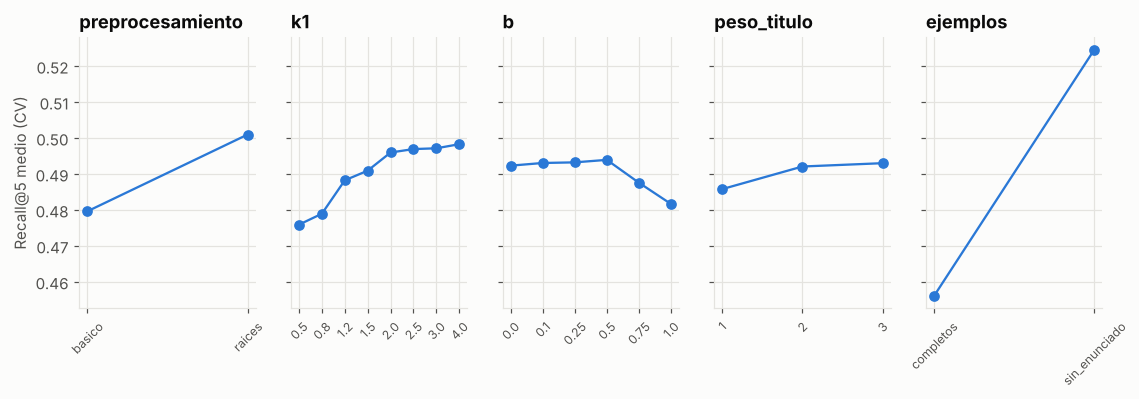

In [10]:
rango = {k: rejilla.groupby(k).recall5_cv.mean().pipe(lambda s: s.max() - s.min()) for k in ho.ESPACIO}
display(pd.Series(rango, name="rango del Recall@5 medio").sort_values(ascending=False).round(3))
fig, axes = plt.subplots(1, 5, figsize=(12, 3.2), sharey=True)
for ax, k in zip(axes, ho.ESPACIO):
    g = rejilla.groupby(k).recall5_cv.mean()
    ax.plot(range(len(g)), g.values, marker="o", color=u.SERIE[0]); ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=45, fontsize=8); ax.set_title(k)
axes[0].set_ylabel("Recall@5 medio (CV)"); plt.show()

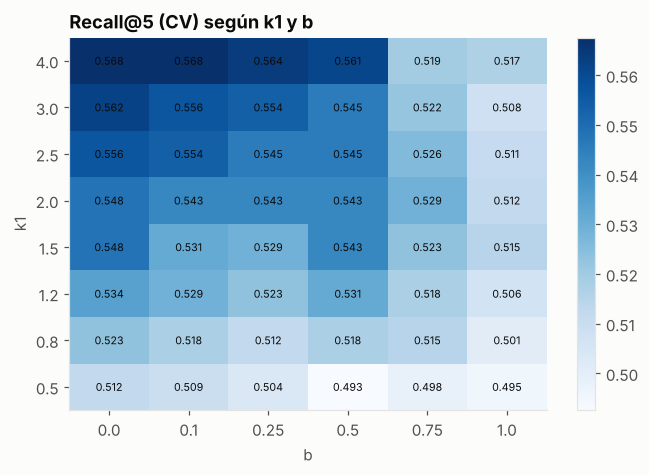

In [11]:
fijo = {k: optima[k] for k in ("preprocesamiento", "peso_titulo", "ejemplos")}
mapa = rejilla[(rejilla[list(fijo)] == pd.Series(fijo)).all(axis=1)].pivot(index="k1", columns="b", values="recall5_cv")
fig, ax = plt.subplots(figsize=(7, 4.4)); im = ax.imshow(mapa.values, cmap="Blues", aspect="auto", origin="lower"); ax.grid(False)
ax.set_xticks(range(mapa.shape[1])); ax.set_xticklabels(mapa.columns); ax.set_yticks(range(mapa.shape[0])); ax.set_yticklabels(mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]): ax.text(j, i, f"{mapa.values[i, j]:.3f}", ha="center", va="center", fontsize=7)
ax.set_xlabel("b"); ax.set_ylabel("k1"); ax.set_title("Recall@5 (CV) según k1 y b"); fig.colorbar(im, ax=ax); plt.show()

Lectura: lo que más pesa es el papel de los ejemplos, porque quitarles el enunciado libera lugares del top-5. En BM25 conviene un k1 alto, que premia que la ficha repita los términos de la pregunta, y un b bajo, que castiga poco la longitud; ambos quedan lejos de los valores estándar de 1,5 y 0,75. El peso del título casi no influye.

## 8. Comparación final en el holdout de validación (una sola vez)

In [12]:
cand = {"vigente": ho.VIGENTE, "solo_bm25": solo_bm25, "optimizada": optima}
res = {n: fe.evaluar(ho.construir(c, corpus), val) for n, c in cand.items()}
filas = []
for n, r in res.items():
    lo, hi = ic_bootstrap(r["recall@5"])
    f = {"candidata": n, "Recall@5": r["recall@5"].mean(), "IC95": f"[{lo:.3f}; {hi:.3f}]", "Recall@1": r["recall@1"].mean(),
         "MRR@10": r["mrr@10"].mean(), "Fallo@5": r["fallo@5"].mean(),
         "práctica": r.loc[r.componente == "practica", "recall@5"].mean(), "teoría": r.loc[r.componente == "teoria", "recall@5"].mean()}
    if n != "vigente":
        d = diferencia_pareada(res["vigente"]["recall@5"], r["recall@5"])
        f.update({"Δ vs vigente": d["diferencia"], "IC95 Δ": f"[{d['ic95'][0]:+.3f}; {d['ic95'][1]:+.3f}]", "p": d["p_bootstrap"]})
    filas.append(f)
pd.DataFrame(filas).set_index("candidata").round(3)

,Recall@5,IC95,Recall@1,MRR@10,Fallo@5,práctica,teoría,Δ vs vigente,IC95 Δ,p
candidata,,,,,,,,,,
vigente,0.444,[0.340; 0.549],0.125,0.314,0.486,0.296,0.889,NaN,NaN,NaN
solo_bm25,0.477,[0.373; 0.583],0.146,0.339,0.444,0.333,0.907,0.032,[-0.019; +0.088],0.261
optimizada,0.581,[0.479; 0.681],0.319,0.504,0.333,0.472,0.907,0.137,[+0.074; +0.206],0.000


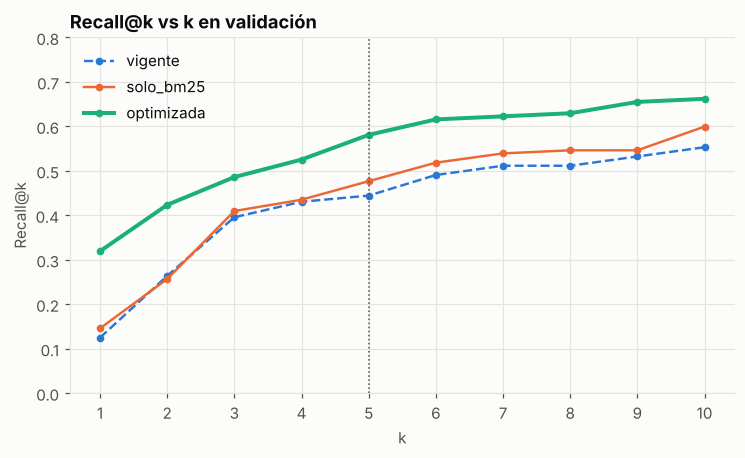

In [13]:
fig, ax = plt.subplots(figsize=(7.8, 4.2))
for i, (n, r) in enumerate(res.items()):
    ax.plot(range(1, 11), [r[f"recall@{k}"].mean() for k in range(1, 11)], "--" if n == "vigente" else "-", marker="o", ms=4,
            color=u.SERIE[i], lw=2.6 if n == "optimizada" else 1.6, label=n)
ax.axvline(5, color=u.TINTA_2, ls=":", lw=1); ax.set_xticks(range(1, 11)); ax.set_ylim(0, 0.8)
ax.set_xlabel("k"); ax.set_ylabel("Recall@k"); ax.set_title("Recall@k vs k en validación"); ax.legend(); plt.show()

## 9. Verificación de cero leakage

In [14]:
salida = subprocess.run([sys.executable, str(RAIZ / "experiments/optimizacion_hiperparametros/verificar_fugas.py")], capture_output=True, text=True, cwd=RAIZ)
print(salida.stdout)
assert json.load(open(ho.R / "verificacion_fugas.json", encoding="utf-8"))["todo_ok"]

bateria_usada → completa (privada) 
1_cv_sin_familias_compartidas → OK {'familias_compartidas': [0, 0, 0, 0, 0], 'ok': True}
2_logs_solo_validacion → OK {'consultas_por_particion': {'validacion': 216}, 'ok': True}
3_evaluacion_final_intacta → OK {'ok': True}
4_textos_protegidos_en_logs → OK {'expuestos': 0, 'ok': True}
todo_ok → True 



## 10. Decisión

Se adopta la configuración optimizada (raíces, k1 = 4,0, b = 0,1, título ×2 y ejemplos sin enunciado), porque el Recall@5 en validación sube de 0,444 a 0,581 (p < 0,001), la CV anidada confirma la mejora sin optimismo en 5 de 5 particiones y el costo es cero. La ganancia viene sobre todo del papel de los ejemplos; ajustar solo BM25 suma unos 3 puntos, que no son significativos. Como cautela, la clave no marca las fichas de ejemplo como esperadas, así que quitarles peso favorece a la métrica por construcción; por eso la decisión es provisional hasta el experimento de generación (LLM con RAG frente a LLM sin RAG). El siguiente paso es congelar esta configuración para ese experimento y probar embeddings como alternativa a BM25.